<a href="https://colab.research.google.com/github/titarzra/Tugas-MachineLearning_TitaRizekyRahmadina_202343500097/blob/main/Bab_04_Feature_Engineering_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Bagian A — Implementasi Python

### Praktikum 4.1 Persiapan Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.linear_model import Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

### Praktikum 4.2 Import Dataset (sintetis properti)

In [2]:
rng = np.random.default_rng(42)
n = 500
df = pd.DataFrame({
    "luas_bangunan": rng.normal(120, 40, n).clip(30, None),
    "jumlah_kamar": rng.integers(1, 6, n),
    "tipe_properti": rng.choice(["Rumah", "Apartemen", "Ruko"], n),
    "kondisi_bangunan": rng.choice(["Buruk", "Sedang", "Baik", "Sangat Baik"], n),
})
df["harga"] = (df["luas_bangunan"] * 15 + df["jumlah_kamar"] * 20 + rng.normal(0, 50, n)) * 1_000_000
df.head()

,luas_bangunan,jumlah_kamar,tipe_properti,kondisi_bangunan,harga
0,132.188683,3,Rumah,Baik,2.047156e+09
1,78.400636,2,Apartemen,Baik,1.232360e+09
2,150.018048,4,Rumah,Sedang,2.290644e+09
3,157.622589,1,Apartemen,Sangat Baik,2.385668e+09
4,41.958592,2,Ruko,Sedang,6.979057e+08


### 4.11 Feature Construction & Preprocessing (ColumnTransformer)

In [3]:
df["rasio_kamar_per_luas"] = df["jumlah_kamar"] / df["luas_bangunan"]

fitur_numerik = ["luas_bangunan", "jumlah_kamar", "rasio_kamar_per_luas"]
fitur_kategorikal = ["tipe_properti"]
fitur_ordinal = ["kondisi_bangunan"]
urutan_kondisi = [["Buruk", "Sedang", "Baik", "Sangat Baik"]]

preprocessor = ColumnTransformer(transformers=[
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), fitur_numerik),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), fitur_kategorikal),
    ("ord", OrdinalEncoder(categories=urutan_kondisi), fitur_ordinal),
])

### 4.12 Training Model (Pipeline Lengkap)

In [4]:
X = df.drop(columns=["harga"])
y = df["harga"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("model", RandomForestRegressor(n_estimators=200, random_state=42)),
])
pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['luas_bangunan',
                                                   'jumlah_kamar',
                                                   'rasio_kamar_per_luas']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['tipe_properti']),
                                                 ('ord',
                                                  OrdinalEncoder(categories=[['Buruk',
                                                                              'Sedang',
                                                                              'Baik',
                                                                              'Sangat '
                                                                              'Baik']]),
                                                  ['kondisi_bangunan'])])),
                ('model',
                 RandomForestRegressor(n_estimators=200, random_state=42))])

### 4.13 Evaluasi

In [5]:
y_pred = pipeline.predict(X_test)
print("R2 Score:", round(r2_score(y_test, y_pred), 3))

R2 Score: 0.987


### 4.14 Visualisasi

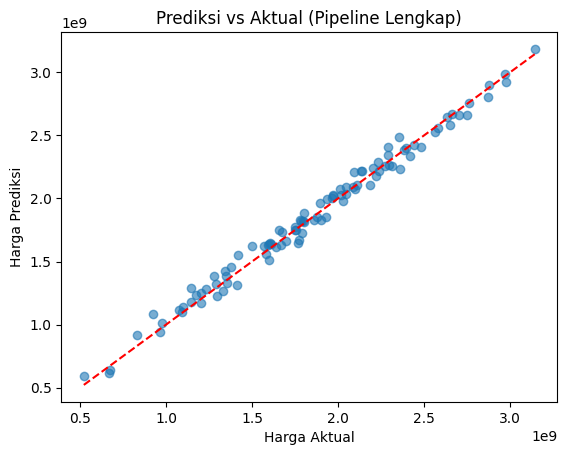

In [6]:
plt.scatter(y_test, y_pred, alpha=0.6)
plt.xlabel("Harga Aktual"); plt.ylabel("Harga Prediksi")
plt.title("Prediksi vs Aktual (Pipeline Lengkap)")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.show()

## Bagian B — Latihan Praktikum

In [7]:
from sklearn.datasets import load_breast_cancer
from sklearn.feature_selection import RFE, SelectFromModel
from sklearn.linear_model import LogisticRegression, LassoCV
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import cross_val_score, StratifiedKFold

data = load_breast_cancer(as_frame=True)
Xc, yc = data.data, data.target
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.2, stratify=yc, random_state=42)
K = 10

# --- Filter: SelectKBest (chi2)
mm = MinMaxScaler().fit(Xc_train)
skb = SelectKBest(chi2, k=K).fit(mm.transform(Xc_train), yc_train)
fitur_filter = set(Xc.columns[skb.get_support()])

# --- Wrapper: RFE
sc = StandardScaler().fit(Xc_train)
Xs_train = sc.transform(Xc_train)
rfe = RFE(LogisticRegression(max_iter=1000), n_features_to_select=K).fit(Xs_train, yc_train)
fitur_rfe = set(Xc.columns[rfe.get_support()])

# --- Embedded: Lasso (alpha dipilih dengan LassoCV pada train set)
lasso_cv = LassoCV(cv=5, random_state=42, max_iter=20000).fit(Xs_train, yc_train)
alpha_lasso = lasso_cv.alpha_
lasso = Lasso(alpha=alpha_lasso, max_iter=20000).fit(Xs_train, yc_train)
fitur_lasso = set(Xc.columns[lasso.coef_ != 0])
print(f"alpha Lasso (LassoCV) = {alpha_lasso:.4f} -> {len(fitur_lasso)} fitur dengan koefisien != 0")

tabel = pd.DataFrame({
    "Filter (chi2)": [f in fitur_filter for f in Xc.columns],
    "Wrapper (RFE)": [f in fitur_rfe for f in Xc.columns],
    "Embedded (Lasso)": [f in fitur_lasso for f in Xc.columns],
}, index=Xc.columns)
tabel["Dipilih oleh (jumlah metode)"] = tabel.sum(axis=1)
tabel.sort_values("Dipilih oleh (jumlah metode)", ascending=False)

alpha Lasso (LassoCV) = 0.0009 -> 23 fitur dengan koefisien != 0


,Filter (chi2),Wrapper (RFE),Embedded (Lasso),Dipilih oleh (jumlah metode)
worst concave points,True,True,True,3
worst radius,True,True,True,3
worst area,True,True,True,3
worst concavity,True,True,True,3
mean area,True,True,False,2
mean concavity,True,False,True,2
radius error,False,True,True,2
worst smoothness,False,True,True,2
worst texture,False,True,True,2
worst perimeter,True,True,False,2


In [8]:
print("Dipilih oleh ketiga metode  :", sorted(fitur_filter & fitur_rfe & fitur_lasso))
print("Irisan Filter & RFE         :", len(fitur_filter & fitur_rfe), "fitur")
print("Irisan Filter & Lasso       :", len(fitur_filter & fitur_lasso), "fitur")
print("Irisan RFE & Lasso          :", len(fitur_rfe & fitur_lasso), "fitur")
print("Gabungan (union)            :", len(fitur_filter | fitur_rfe | fitur_lasso), "fitur")

Dipilih oleh ketiga metode  : ['worst area', 'worst concave points', 'worst concavity', 'worst radius']
Irisan Filter & RFE         : 6 fitur
Irisan Filter & Lasso       : 6 fitur
Irisan RFE & Lasso          : 8 fitur
Gabungan (union)            : 27 fitur


In [9]:
# Evaluasi kualitas: selector di dalam Pipeline (tanpa leakage)
alpha_pakai = alpha_lasso
konfig = {
    "Semua fitur (30)": Pipeline([("sc", StandardScaler()), ("clf", LogisticRegression(max_iter=1000))]),
    "Filter (chi2, k=10)": Pipeline([("mm", MinMaxScaler()), ("sel", SelectKBest(chi2, k=K)),
                                     ("clf", LogisticRegression(max_iter=1000))]),
    "Wrapper (RFE, k=10)": Pipeline([("sc", StandardScaler()),
                                     ("sel", RFE(LogisticRegression(max_iter=1000), n_features_to_select=K)),
                                     ("clf", LogisticRegression(max_iter=1000))]),
    "Embedded (Lasso)": Pipeline([("sc", StandardScaler()),
                                  ("sel", SelectFromModel(Lasso(alpha=alpha_pakai, max_iter=20000), threshold=1e-8)),
                                  ("clf", LogisticRegression(max_iter=1000))]),
}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
baris = []
for nama, pipe in konfig.items():
    cv = cross_val_score(pipe, Xc_train, yc_train, cv=skf, scoring="accuracy")
    pipe.fit(Xc_train, yc_train)
    baris.append({"Metode": nama, "Akurasi CV": cv.mean(), "Std CV": cv.std(),
                  "Akurasi Test": pipe.score(Xc_test, yc_test)})
pd.DataFrame(baris).set_index("Metode").round(3)

,Akurasi CV,Std CV,Akurasi Test
Metode,,,
Semua fitur (30),0.978,0.010,0.982
"Filter (chi2, k=10)",0.941,0.015,0.947
"Wrapper (RFE, k=10)",0.965,0.011,0.974
Embedded (Lasso),0.971,0.015,0.982


In [10]:
import seaborn as sns

titanic = sns.load_dataset("titanic")
print("Ukuran data:", titanic.shape)
print("Missing value (kolom terpilih):\n", titanic[["age", "fare", "sex", "embarked", "survived"]].isnull().sum())

fitur_num = ["age", "fare"]
fitur_cat = ["sex", "embarked"]
Xt = titanic[fitur_num + fitur_cat]
yt = titanic["survived"]
Xt_train, Xt_test, yt_train, yt_test = train_test_split(Xt, yt, test_size=0.2, stratify=yt, random_state=42)

prep_titanic = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), fitur_num),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), fitur_cat),
])

from sklearn.ensemble import RandomForestClassifier
pipe_lr = Pipeline([("prep", prep_titanic), ("clf", LogisticRegression(max_iter=1000))])
pipe_rf = Pipeline([("prep", prep_titanic), ("clf", RandomForestClassifier(n_estimators=300, max_depth=5, random_state=42))])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
baris = []
for nama, pipe in [("Logistic Regression", pipe_lr), ("Random Forest (max_depth=5)", pipe_rf)]:
    cv = cross_val_score(pipe, Xt_train, yt_train, cv=skf, scoring="accuracy")
    pipe.fit(Xt_train, yt_train)
    baris.append({"Model": nama, "Akurasi CV": cv.mean(), "Std CV": cv.std(),
                  "Akurasi Test": pipe.score(Xt_test, yt_test)})
pd.DataFrame(baris).set_index("Model").round(3)

Ukuran data: (891, 15)
Missing value (kolom terpilih):
 age         177
fare          0
sex           0
embarked      2
survived      0
dtype: int64


,Akurasi CV,Std CV,Akurasi Test
Model,,,
Logistic Regression,0.782,0.021,0.777
Random Forest (max_depth=5),0.791,0.022,0.765


In [11]:
# Bukti bahwa pipeline menangani data mentah baru (termasuk nilai hilang) tanpa preprocessing manual
penumpang_baru = pd.DataFrame([
    {"age": 28, "fare": 70.0, "sex": "female", "embarked": "C"},
    {"age": np.nan, "fare": 7.9, "sex": "male", "embarked": np.nan},   # age & embarked hilang
])
print("Prediksi (1=selamat):", pipe_lr.predict(penumpang_baru))
print("Probabilitas selamat :", pipe_lr.predict_proba(penumpang_baru)[:, 1].round(3))

Prediksi (1=selamat): [1 0]
Probabilitas selamat : [0.871 0.14 ]
